### Questions auxquelles l’analyse cherche à répondre

1. Quelles sont les variables catégorielles et numériques qui présentent des relations entre elles ?

2. Quels sont les 10 genres de films les plus représentés dans le dataset ?

3. Quels sont les 10 films ayant généré les plus importantes recettes au box-office mondial ?

4. Quelle est l’évolution du nombre de films produits au fil des années ?

5. Quels sont les films ayant obtenu les meilleures évaluations de la part des critiques et du public ?


In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency


In [26]:
numbers_rotten_100 = pd.read_csv("../../data/merged/manual_merge/final_manual_merge_rotten_numbers.csv")

In [27]:
numbers_rotten_100.head()

,rank,title,year,domestic_box_office,international_box_office,worldwide_box_office,domestic_share,title_rotten,summary,director,...,audience_score_percentage,is_audience_rating_verified,audience_rating_count,audience_rating_count_operator,release_type_theater,year_rotten,runtime_hour,runtime_minutes,format_ratio,aspect_ratio
0,1,Avengers: Endgame,2019,862173000.0,1.859131e+09,2.721304e+09,31.7,Avengers: Endgame,"Adrift in space with no food or water, Tony St...","Anthony Russo, Joe Russo",...,96.0,True,1000.0,>=,Wide,2019.0,3.0,1.0,Digital,2.39:1
1,63,Poor Things,2023,34553225.0,8.307223e+07,1.176255e+08,29.4,Poor Things,From filmmaker Yorgos Lanthimos and producer E...,Yorgos Lanthimos,...,80.0,True,1000.0,>=,Limited,2023.0,2.0,21.0,Flat,1.66:1
2,42,The Addams Family,2019,97864733.0,1.027238e+08,2.005885e+08,48.8,The Addams Family,Members of the mysterious and spooky Addams Fa...,"Conrad Vernon, Greg Tiernan",...,70.0,True,10000.0,>=,Wide,2019.0,1.0,26.0,Flat,1.85:1
3,40,Ford v. Ferrari,2019,117624357.0,1.067663e+08,2.243907e+08,52.4,Ford v Ferrari,American automotive designer Carroll Shelby an...,James Mangold,...,98.0,True,10000.0,>=,Wide,2019.0,2.0,32.0,Scope,2.35:1
4,39,Annabelle Comes Home,2019,74152591.0,1.571000e+08,2.312526e+08,32.1,Annabelle Comes Home,Determined to keep Annabelle from wreaking mor...,Gary Dauberman,...,70.0,True,5000.0,>=,Wide,2019.0,1.0,46.0,Scope,2.35:1


In [28]:
numbers_rotten_100.isna().sum().sort_values(ascending=False)

creator                           126
aspect_ratio                       59
format_ratio                       59
sound mix                          31
production co                      18
screenwriter                       11
critic_score_percentage             7
rating                              6
audience_score_percentage           4
producer                            4
distributor                         3
title_rotten                        2
year_rotten                         2
worldwide_box_office                0
year                                0
runtime_minutes                     0
runtime_hour                        0
release_type_theater                0
audience_rating_count_operator      0
audience_rating_count               0
is_audience_rating_verified         0
domestic_box_office                 0
critic_reviews_count                0
domestic_share                      0
international_box_office            0
title                               0
original lan

In [29]:
# drop create column cause 100% of values are null
numbers_rotten_100 = numbers_rotten_100.drop(columns=["creator"],axis=0)

In [30]:
numbers_rotten_100.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 30 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   rank                            126 non-null    int64  
 1   title                           126 non-null    object 
 2   year                            126 non-null    int64  
 3   domestic_box_office             126 non-null    float64
 4   international_box_office        126 non-null    float64
 5   worldwide_box_office            126 non-null    float64
 6   domestic_share                  126 non-null    float64
 7   title_rotten                    124 non-null    object 
 8   summary                         126 non-null    object 
 9   director                        126 non-null    object 
 10  producer                        122 non-null    object 
 11  distributor                     123 non-null    object 
 12  genre                           126 

In [31]:
numbers_rotten_100.describe()

,rank,year,domestic_box_office,international_box_office,worldwide_box_office,domestic_share,critic_reviews_count,critic_score_percentage,audience_score_percentage,audience_rating_count,year_rotten,runtime_hour,runtime_minutes
count,126.000000,126.000000,1.260000e+02,1.260000e+02,1.260000e+02,126.000000,126.000000,119.000000,122.000000,126.000000,124.000000,126.000000,126.000000
mean,44.341270,2022.222222,8.946138e+07,1.668000e+08,2.562614e+08,40.572222,210.793651,67.142857,80.844262,7212.301587,2022.217742,1.357143,34.555556
std,29.544316,3.281192,1.321382e+08,2.472745e+08,3.630388e+08,24.123140,147.777255,23.074047,15.420830,13351.991142,3.277319,0.528610,17.173261
min,1.000000,2019.000000,0.000000e+00,0.000000e+00,1.262417e+07,0.000000,0.000000,11.000000,28.000000,0.000000,2019.000000,1.000000,0.000000
25%,17.000000,2019.000000,1.371981e+07,2.827673e+07,4.810702e+07,29.025000,88.250000,52.000000,71.250000,1000.000000,2019.000000,1.000000,25.000000
50%,40.000000,2020.000000,4.693806e+07,6.939300e+07,1.313357e+08,41.250000,205.000000,72.000000,86.000000,2500.000000,2020.000000,1.000000,38.500000
75%,67.000000,2026.000000,9.761202e+07,1.937615e+08,2.938889e+08,52.175000,328.500000,86.000000,94.000000,10000.000000,2026.000000,2.000000,48.000000
max,99.000000,2026.000000,8.621730e+08,1.859131e+09,2.721304e+09,100.000000,581.000000,100.000000,100.000000,100000.000000,2026.000000,3.000000,59.000000


# Analyse de world wide box office 

<Axes: xlabel='worldwide_box_office'>

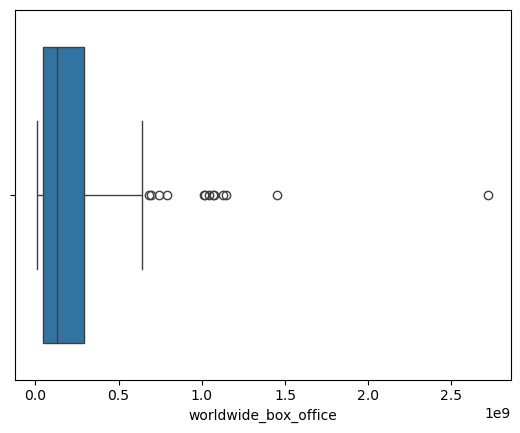

In [32]:
sns.boxplot(x=numbers_rotten_100["worldwide_box_office"])

Le boxplot montre que la distribution des **recettes mondiales des films** est fortement **asymétrique à droite**.

- La majorité des films génèrent des recettes relativement faibles, principalement situées entre **0,05 et 0,30 milliard de dollars**.
- La **médiane** se situe autour de **0,13 milliard de dollars**, ce qui signifie que 50 % des films ont des recettes inférieures à cette valeur et 50 % ont des recettes supérieures.
- Plusieurs **valeurs aberrantes (outliers)** sont visibles au-delà de cette limite, avec certaines recettes dépassant **1 milliard de dollars**.
- Une valeur particulièrement élevée atteint environ **2,7 milliards de dollars**, ce qui correspond à un film ayant réalisé un succès commercial exceptionnel.
.

## Calculate relationships between numerical variables with pearson

In [33]:
numeric_cols = [
    'rank',
    'year',
    'domestic_box_office',
    'international_box_office',
    'worldwide_box_office',
    'domestic_share',
    'critic_reviews_count',
    'critic_score_percentage',
    'audience_score_percentage',
    'audience_rating_count',
    'year_rotten',
    'runtime_hour',
    'runtime_minutes',
    
]


corr = numbers_rotten_100[numeric_cols].corr(method='pearson')
corr

,rank,year,domestic_box_office,international_box_office,worldwide_box_office,domestic_share,critic_reviews_count,critic_score_percentage,audience_score_percentage,audience_rating_count,year_rotten,runtime_hour,runtime_minutes
rank,1.000000,0.025784,-0.537652,-0.620245,-0.618158,0.319045,-0.334043,-0.083313,-0.210824,-0.405376,0.010086,-0.314191,0.226518
year,0.025784,1.000000,-0.169433,-0.165082,-0.174111,-0.002135,-0.324600,0.067799,0.149034,-0.308692,1.000000,-0.013837,0.130962
domestic_box_office,-0.537652,-0.169433,1.000000,0.813971,0.918393,0.075601,0.573655,0.143736,0.175986,0.609078,-0.162565,0.288420,-0.235831
international_box_office,-0.620245,-0.165082,0.813971,1.000000,0.977392,-0.285347,0.322902,0.156867,0.187179,0.439056,-0.159040,0.347440,-0.282829
worldwide_box_office,-0.618158,-0.174111,0.918393,0.977392,1.000000,-0.166840,0.428734,0.157944,0.191177,0.520743,-0.167523,0.341629,-0.278479
domestic_share,0.319045,-0.002135,0.075601,-0.285347,-0.166840,1.000000,0.232241,0.026960,0.028787,0.033711,-0.002227,-0.188492,0.051578
critic_reviews_count,-0.334043,-0.324600,0.573655,0.322902,0.428734,0.232241,1.000000,0.337249,0.030587,0.547689,-0.308551,0.216834,-0.063943
critic_score_percentage,-0.083313,0.067799,0.143736,0.156867,0.157944,0.026960,0.337249,1.000000,0.364895,0.103951,0.064360,0.083812,0.015219
audience_score_percentage,-0.210824,0.149034,0.175986,0.187179,0.191177,0.028787,0.030587,0.364895,1.000000,0.000790,0.135345,0.160294,0.001443
audience_rating_count,-0.405376,-0.308692,0.609078,0.439056,0.520743,0.033711,0.547689,0.103951,0.000790,1.000000,-0.299080,0.215525,-0.228150


réponse qst 1: 
Domestic box-office ↔ Audience rating count : r = 0,609
Cette corrélation de 0,609 indique une corrélation positive forte entre les revenus du film sur le marché domestique et le nombre d'évaluations laissées par le public.



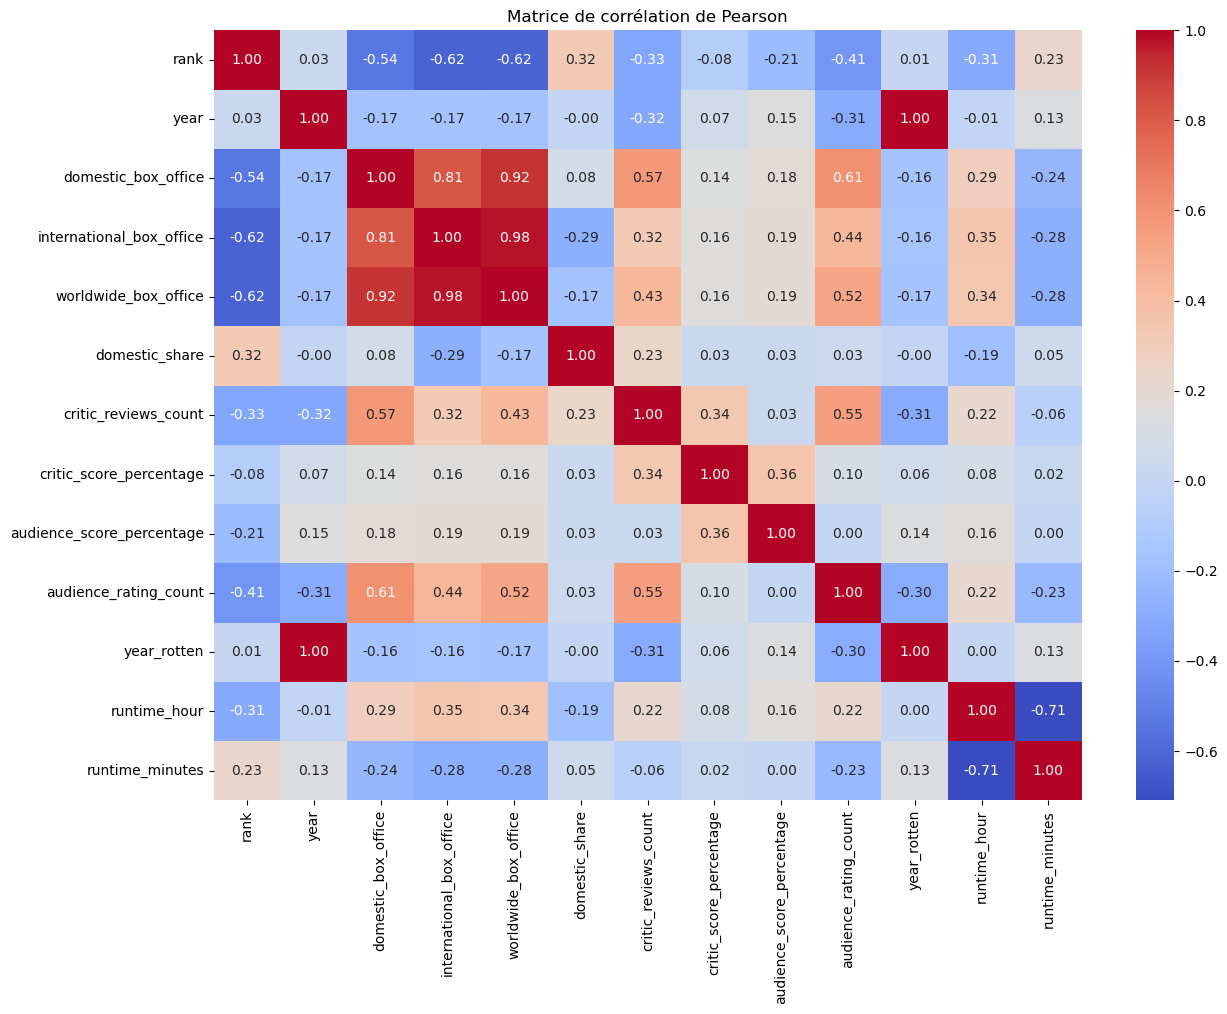

In [34]:


plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Matrice de corrélation de Pearson")
plt.show()

- worldwide_box_office et audience_rating_count (r = 0,52) : corrélation positive modérée. Les films générant davantage de recettes tendent à recevoir plus d'évaluations du public.
- worldwide_box_office et critic_reviews_count (r = 0,43) : corrélation positive modérée. Les films ayant davantage de critiques publiées tendent à générer plus de recettes.

## Study the relationship between two categorical variables.

In [35]:
categorical_cols = numbers_rotten_100.select_dtypes(include=['object', 'category', 'bool']).columns

categorical_cols.tolist()


['title',
 'title_rotten',
 'summary',
 'director',
 'producer',
 'distributor',
 'genre',
 'original language',
 'screenwriter',
 'production co',
 'rating',
 'sound mix',
 'is_audience_rating_verified',
 'audience_rating_count_operator',
 'release_type_theater',
 'format_ratio',
 'aspect_ratio']

In [36]:
chi2_results = []

for i in range(len(categorical_cols)):
    for j in range(i + 1, len(categorical_cols)):
        
        col1 = categorical_cols[i]
        col2 = categorical_cols[j]
        
        # Remove missing values
        temp = numbers_rotten_100[[col1, col2]].dropna()
        
        # Contingency table
        table = pd.crosstab(temp[col1], temp[col2])
        
        # Chi² test
        chi2, p_value, dof, expected = chi2_contingency(table)
        
        chi2_results.append({
            'variable_1': col1,
            'variable_2': col2,
            'chi2': chi2,
            'p_value': p_value,
            
        })

chi2_df = pd.DataFrame(chi2_results)

chi2_df[chi2_df["p_value"]<0.05]

,variable_1,variable_2,chi2,p_value
58,producer,distributor,5184.280769,4.762512e-02
71,distributor,original language,388.925234,1.981845e-17
73,distributor,production co,3759.594373,1.427601e-02
75,distributor,sound mix,1892.017772,5.661390e-04
77,distributor,audience_rating_count_operator,121.175847,1.586986e-02
78,distributor,release_type_theater,102.269719,2.399686e-06
83,genre,production co,6710.090909,1.469183e-02
87,genre,audience_rating_count_operator,225.966942,6.709769e-04
94,original language,sound mix,190.000000,1.875872e-06
95,original language,is_audience_rating_verified,12.812976,1.222672e-02


réponse q1:
Distributor ↔ Original language

Il existe une association statistiquement significative entre le distributeur et la langue originale du film. Cela peut s'expliquer par le fait que certains distributeurs sont spécialisés dans certaines productions nationales ou certains marchés linguistiques.

réponse q2

In [37]:
numbers_rotten_100["rank"]

0       1
1      63
2      42
3      40
4      39
       ..
121    96
122    45
123    48
124    23
125    77
Name: rank, Length: 126, dtype: int64

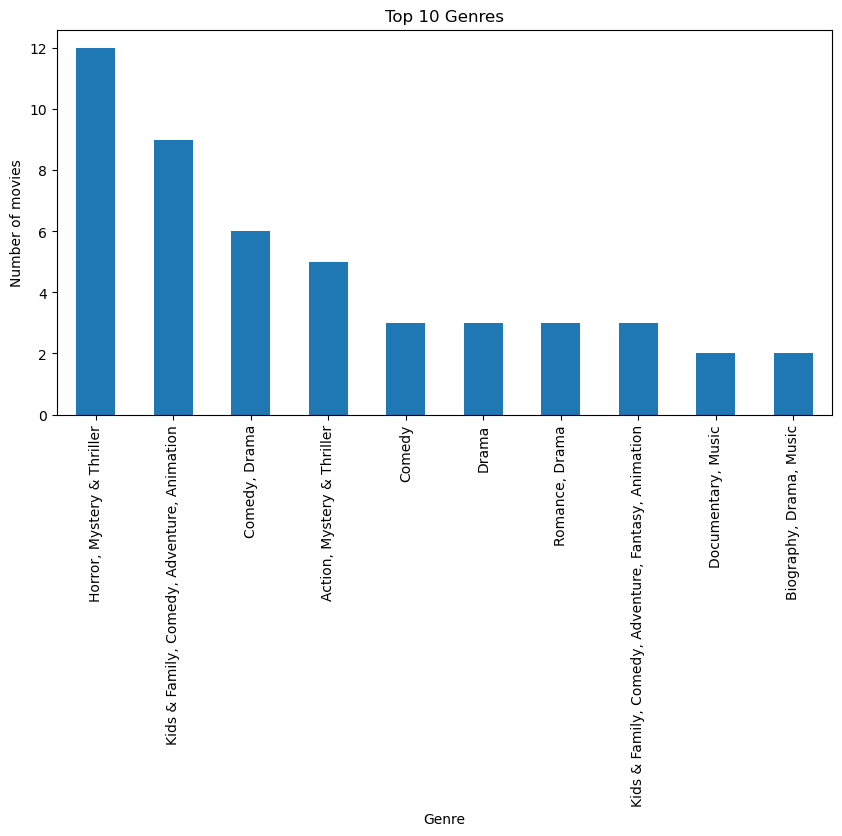

In [38]:
numbers_rotten_100['genre'].value_counts().head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Top 10 Genres")
plt.xlabel("Genre")
plt.ylabel("Number of movies")
plt.show()

# réponse q3

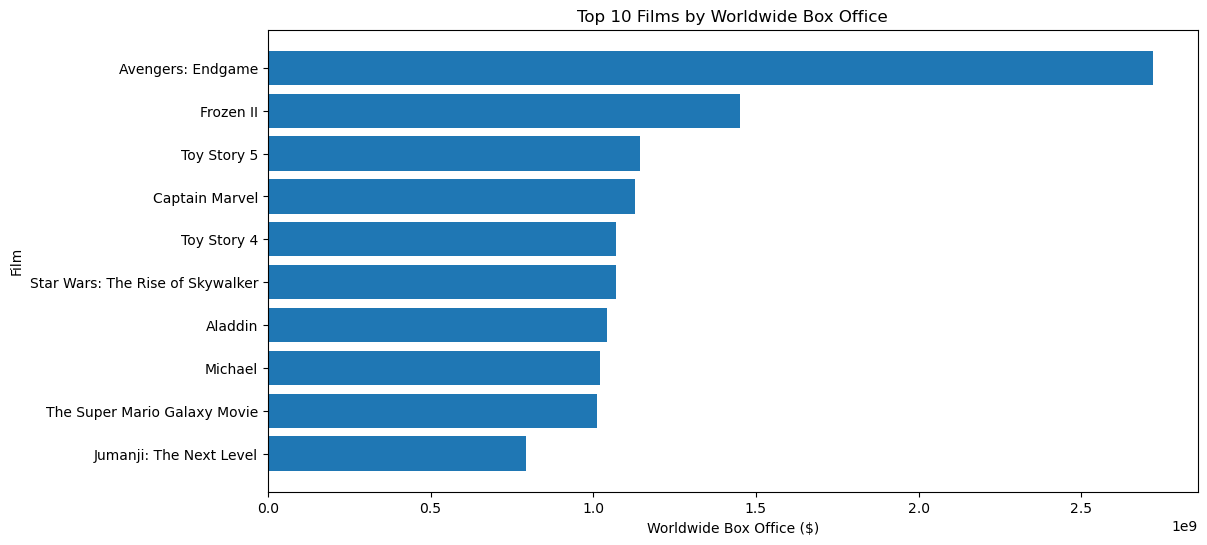

In [39]:
top_10 = (
    numbers_rotten_100[['title', 'worldwide_box_office']]
    .dropna(subset=['worldwide_box_office'])
    .sort_values('worldwide_box_office', ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_10['title'][::-1],
    top_10['worldwide_box_office'][::-1]
)

plt.xlabel('Worldwide Box Office ($)')
plt.ylabel('Film')
plt.title('Top 10 Films by Worldwide Box Office')

plt.show()

# réponse q4

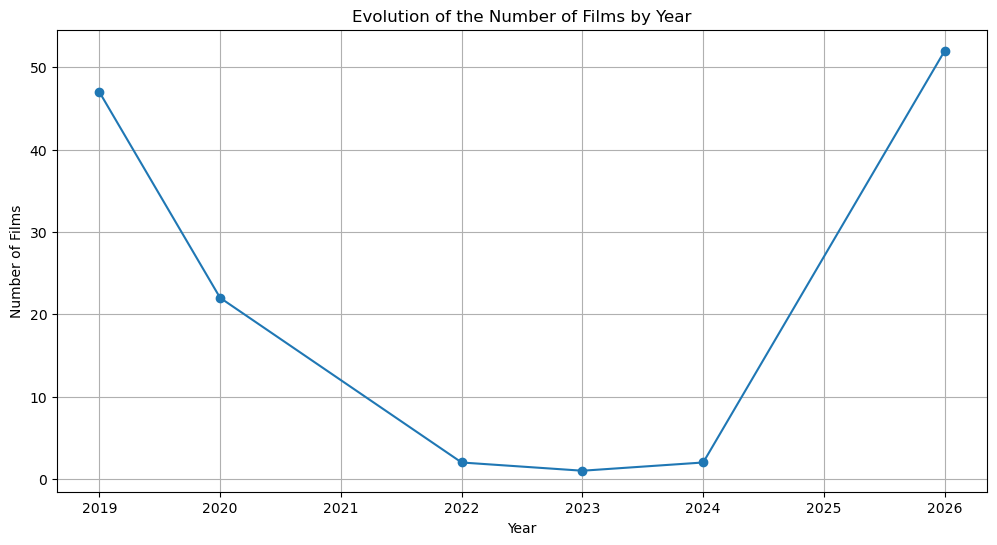

In [40]:
films_by_year = (
    numbers_rotten_100.groupby('year')
      .size()
      .sort_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    films_by_year.index,
    films_by_year.values,
    marker='o'
)

plt.title('Evolution of the Number of Films by Year')
plt.xlabel('Year')
plt.ylabel('Number of Films')
plt.grid(True)

plt.show()

# réponse q5

,title,critic_reviews_count,critic_score_percentage,audience_score_percentage,audience_rating_count
54,Stray Kids: The DominATE experience,9.0,NaN,100.0,1000.0
74,I Can Only Imagine 2,25.0,60.0,99.0,1000.0
118,I Still Believe,48.0,50.0,98.0,1000.0
3,Ford v. Ferrari,364.0,92.0,98.0,10000.0
78,Dear You (给阿嬷的情书),22.0,91.0,98.0,100.0
43,Ne Zha (哪吒之魔童降世),20.0,90.0,98.0,250.0
125,Billie Eilish - Hit Me Hard and Soft: The Tour...,83.0,92.0,97.0,1000.0
85,Pegasus 3 (飞驰人生3),4.0,NaN,97.0,50.0
71,All Wishes Come True! (八仙！),11.0,100.0,97.0,50.0
53,EPiC: Elvis Presley in Concert,120.0,97.0,97.0,1000.0


C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39134 (\N{CJK UNIFIED IDEOGRAPH-98DE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39536 (\N{CJK UNIFIED IDEOGRAPH-9A70}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20843 (\N{CJK UNIF

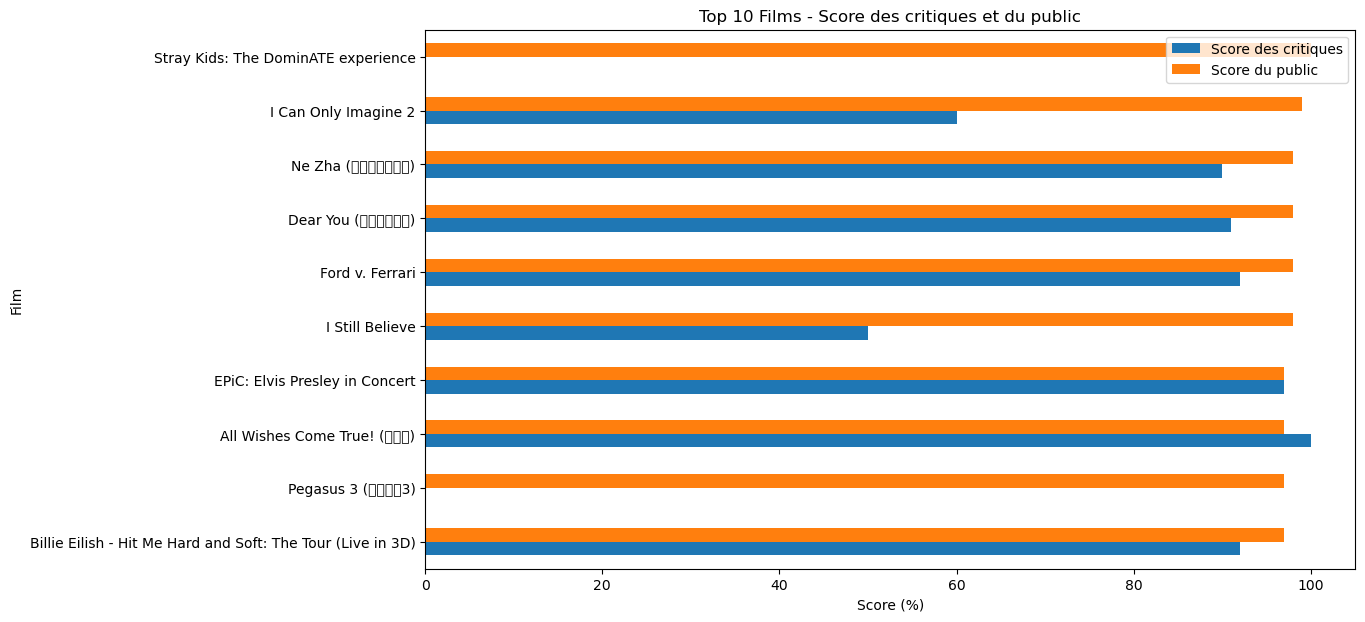

C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39134 (\N{CJK UNIFIED IDEOGRAPH-98DE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39536 (\N{CJK UNIFIED IDEOGRAPH-9A70}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20843 (\N{CJK UNIF

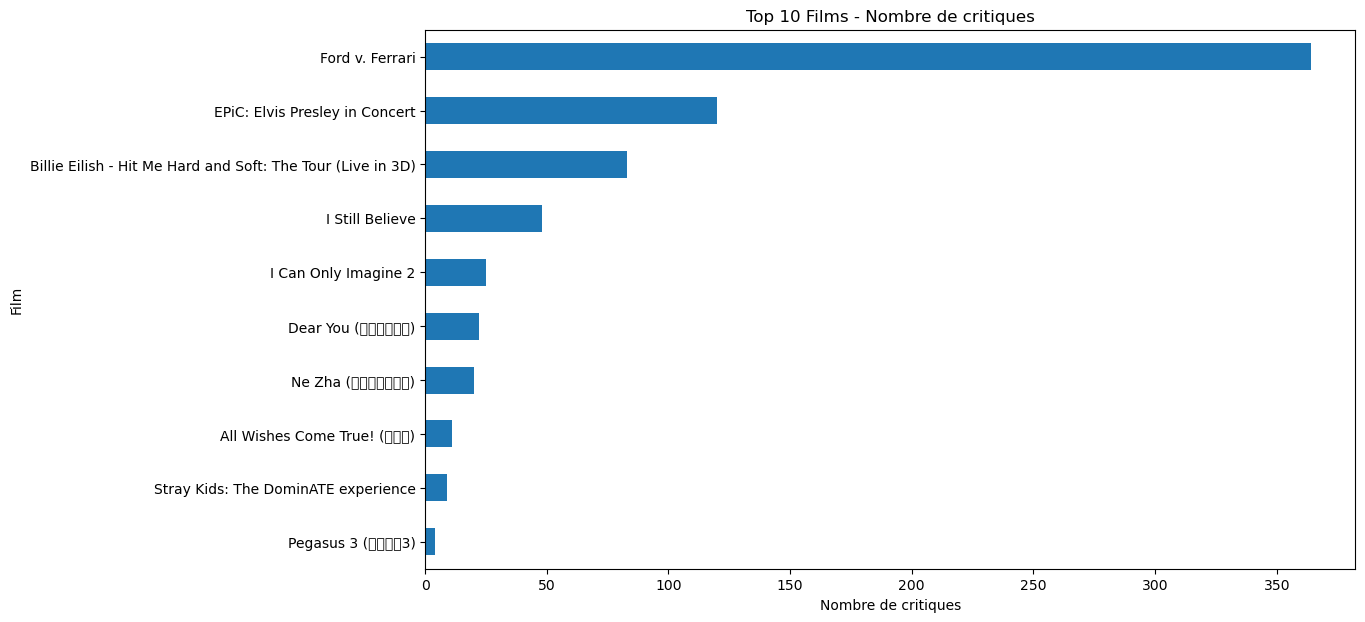

C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39134 (\N{CJK UNIFIED IDEOGRAPH-98DE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 39536 (\N{CJK UNIFIED IDEOGRAPH-9A70}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\oo\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20843 (\N{CJK UNIF

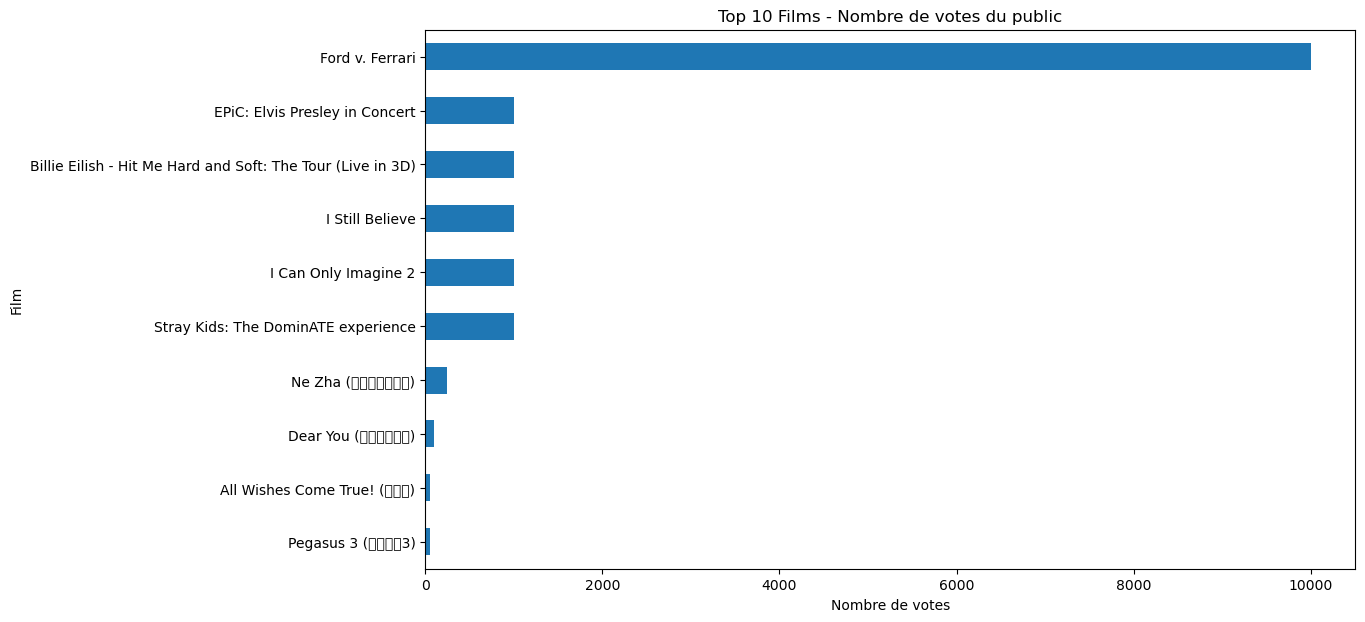

In [41]:

top_10_films = (
    numbers_rotten_100[
        [
            'title',
            'critic_reviews_count',
            'critic_score_percentage',
            'audience_score_percentage',
            'audience_rating_count'
        ]
    ]
    .dropna(subset=['audience_score_percentage'])
    .sort_values('audience_score_percentage', ascending=False)
    .head(10)
)

display(top_10_films)


top_10_films_plot = top_10_films.set_index('title')

top_10_films_plot[
    ['critic_score_percentage', 'audience_score_percentage']
].sort_values(
    'audience_score_percentage'
).plot(
    kind='barh',
    figsize=(12, 7)
)

plt.title('Top 10 Films - Score des critiques et du public')
plt.xlabel('Score (%)')
plt.ylabel('Film')
plt.legend([
    'Score des critiques',
    'Score du public'
])

plt.show()


top_10_films_plot[
    'critic_reviews_count'
].sort_values().plot(
    kind='barh',
    figsize=(12, 7)
)

plt.title('Top 10 Films - Nombre de critiques')
plt.xlabel('Nombre de critiques')
plt.ylabel('Film')

plt.show()


top_10_films_plot[
    'audience_rating_count'
].sort_values().plot(
    kind='barh',
    figsize=(12, 7)
)

plt.title('Top 10 Films - Nombre de votes du public')
plt.xlabel('Nombre de votes')
plt.ylabel('Film')

plt.show()